# Pretrained Transfer Learning with Source Pretraining, Target Fine-Tuning, and Layer-wise PC Tracking

## Task Description
Implementation of a two-stage transfer learning pipeline based on Di et al. (2025):
1. **Target Fixed Subsets Setup**:
   - At initialization, draw and fix `SAMPLE_SIZES` instances from the target dataset `NUM_REPLICATIONS` times with fixed random seeds for reproducible target validation loss and layer-wise Projection Correlation (PC) evaluation with confidence intervals.
2. **Stage 1 (Source Pretraining)**:
   - Train a 6-layer CNN on the source dataset.
   - Early stopping on source validation loss with patience `EARLY_STOP_PATIENCE` (=5).
   - Upon trigger, run an extra `POST_EARLY_STOP_EPOCHS` (=10) control epochs.
   - At each epoch, evaluate and log: Train Loss, Source Test Accuracy, Source Validation Loss, Target Validation Loss, Layer-wise PC ($\omega_j$) with 95% CI.
   - Select best source model: by Source Val Loss or by PC generality.
3. **Stage 2 (Target Fine-Tuning across 7 Models $M_0 \dots M_6$)**:
   - Transfer first $k$ layers ($k \in \{0, 1, 2, 3, 4, 5, 6\}$).
   - Target training on fixed sample subset (`SAMPLE_SIZES`).
   - Early stopping monitored on Target Validation Loss with patience `TARGET_PATIENCE` (=5).
   - Log each epoch: Train Loss, Test Accuracy, Target Val Loss, Layer-wise PC.

## 1. Environment Setup, Google Colab Integration & GPU Verification

In [1]:
import os
import sys
import time
import json
import glob
from datetime import datetime
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt


def setup_environment(seed: int = 42) -> Tuple[torch.device, int]:
    """Setup device, random seeds, and Google Colab environment / Drive mount.

    Parameters
    ----------
    seed : int
        Base random seed for reproducibility.

    Returns
    -------
    Tuple[torch.device, int]
        (device, seed) where device is cuda or cpu.
    """
    import random
    if "google.colab" in sys.modules:
        print("[Colab] Google Colab environment detected.")
        target_dir = None

        # 1. Check if repository is already in current working directory or /content/Di
        for path in [os.getcwd(), '/content/Di', '/content']:
            if os.path.exists(os.path.join(path, 'models.py')) and os.path.exists(os.path.join(path, 'di_algorithm.py')):
                target_dir = path
                break

        # 2. If not found, try searching in Google Drive
        if target_dir is None:
            try:
                from google.colab import drive
                drive.mount('/content/drive')
                candidates = [
                    '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di',
                    '/content/drive/MyDrive/Diplom/var1_Di/code/Di',
                    '/content/drive/MyDrive/var1_Di/code/Di',
                    '/content/drive/MyDrive/code/Di',
                    '/content/drive/MyDrive/Di',
                ]
                for cand in candidates:
                    if os.path.isdir(cand) and os.path.exists(os.path.join(cand, 'models.py')):
                        target_dir = cand
                        break

                if target_dir is None and os.path.isdir('/content/drive/MyDrive'):
                    print("[Colab] Searching for project folder in Google Drive...")
                    for root, dirs, files in os.walk('/content/drive/MyDrive'):
                        if 'models.py' in files and 'di_algorithm.py' in files:
                            target_dir = root
                            break
            except Exception as e:
                print(f"[Colab] Google Drive search skipped/failed: {e}")

        # 3. If still not found, clone repository directly from GitHub
        if target_dir is None:
            print("[Colab] Repository files not found locally or in Drive. Cloning from GitHub...")
            import subprocess
            subprocess.run(['git', 'clone', 'https://github.com/DR24DR24/Di.git', '/content/Di'], check=False)
            if os.path.exists('/content/Di/models.py'):
                target_dir = '/content/Di'

        if target_dir:
            os.chdir(target_dir)
            if target_dir not in sys.path:
                sys.path.insert(0, target_dir)
            print(f"[Colab] Working directory set to: {os.getcwd()}")
        else:
            cd = os.path.dirname(os.path.abspath("__file__")) if "__file__" in locals() else os.getcwd()
            if cd not in sys.path:
                sys.path.insert(0, cd)
            print(f"[Colab] WARNING: 'models.py' not found! Current directory: {os.getcwd()}")
    else:
        cd = os.path.dirname(os.path.abspath("__file__")) if "__file__" in locals() else os.getcwd()
        if cd not in sys.path:
            sys.path.insert(0, cd)
        print(f"[Local] Working directory: {os.getcwd()}")

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Device: {device}")
    if torch.cuda.is_available():
        print(f"GPU: {torch.cuda.get_device_name(0)}")
        print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Random seed fixed: {seed}")
    return device, seed


# Execute environment setup immediately when Cell 3 runs
device, seed = setup_environment(seed=42)


[Colab] Google Colab environment detected.
Mounted at /content/drive
[Colab] Searching for project folder in Google Drive...
[Colab] Working directory set to: /content/drive/MyDrive/git/Di
Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB
Random seed fixed: 42


## 2. Experiment Parameters, Named Constants & Output Directory

In [2]:
def get_timestamp() -> str:
    """Return a compact timestamp string YYYYMMDD_HHMMSS."""
    return datetime.now().strftime("%Y%m%d_%H%M%S")


def make_result_path(base_name: str, ext: str, ts: Optional[str] = None, results_dir: Optional[str] = None) -> str:
    """Generate a full output file path with timestamp in the results directory."""
    if ts is None:
        ts = get_timestamp()
    filename = f"{base_name}_{ts}.{ext}"
    if results_dir is None:
        results_dir = os.path.join(os.getcwd(), "pretrained")
    os.makedirs(results_dir, exist_ok=True)
    return os.path.join(results_dir, filename)


def get_experiment_params(
    experiment_case: str = 'imbalance',
    sample_sizes: Optional[List[int]] = None,
    num_replications: int = 10,
    use_real_cifar10: bool = True,
    pretrain_epochs: int = 50,
    early_stop_patience: int = 5,
    post_early_stop_epochs: int = 1,
    learning_rate_source: float = 0.001,
    target_epochs: int = 50,
    target_patience: int = 5,
    learning_rate_target: float = 0.001,
    feature_extraction: bool = True,
    ft_sample_size: Optional[int] = 1000,
    best_model_criterion: str = 'pc',
    notebook_name: str = "pretrained",
    seed: int = 42,
) -> Dict[str, Any]:
    """Return all experiment parameters as a dictionary."""
    if sample_sizes is None:
        sample_sizes = [200]

    results_dir = os.path.join(os.getcwd(), notebook_name)
    os.makedirs(results_dir, exist_ok=True)

    params = {
        "EXPERIMENT_CASE": experiment_case,
        "SAMPLE_SIZES": sample_sizes,
        "NUM_REPLICATIONS": num_replications,
        "USE_REAL_CIFAR10": use_real_cifar10,
        "PRETRAIN_EPOCHS": pretrain_epochs,
        "EARLY_STOP_PATIENCE": early_stop_patience,
        "POST_EARLY_STOP_EPOCHS": post_early_stop_epochs,
        "LEARNING_RATE_SOURCE": learning_rate_source,
        "TARGET_EPOCHS": target_epochs,
        "TARGET_PATIENCE": target_patience,
        "LEARNING_RATE_TARGET": learning_rate_target,
        "FEATURE_EXTRACTION": feature_extraction,
        "FT_SAMPLE_SIZE": ft_sample_size,
        "BEST_MODEL_CRITERION": best_model_criterion,
        "NOTEBOOK_NAME": notebook_name,
        "RESULTS_DIR": results_dir,
        "SEED": seed,
    }

    print(f"Results Directory: {params['RESULTS_DIR']}")
    print(f"Mode: {params['EXPERIMENT_CASE']} | Sample sizes: {params['SAMPLE_SIZES']} | Replications: {params['NUM_REPLICATIONS']}")
    print(f"Post early-stopping control epochs: {params['POST_EARLY_STOP_EPOCHS']}")

    return params


## 3. Data Loading, Class Splitting, and DataLoaders

In [3]:
from models import CIFAR6CNN, create_transferred_model, set_trainable_layers
from dataset_splits import (
    split_cifar_imbalance,
    split_cifar_balance,
    generate_synthetic_transfer_dataset,
    make_dataloaders,
    create_ft_dataloader_from_subsets
)
from di_algorithm import default_eval_loss
from projection_correlation import projection_correlation, save_experiment_results
from layer_extractor import extract_layer_activations


def load_experiment_data(
    experiment_case: str = "imbalance",
    seed: int = 42,
    use_real_cifar10: bool = True,
    n_source: int = 1200,
    n_target: int = 800,
    batch_size: int = 64,
    data_dir: str = './data'
) -> Dict[str, Any]:
    """Load data, split into source/target, create dataloaders.

    Returns dict with keys: splits, loaders, target_train_x, target_train_y,
    target_test_loader, generator, num_source_classes, num_target_classes.
    """
    if use_real_cifar10:
        from cifar10_experiment import load_cifar10_raw
        print("Loading CIFAR-10 dataset...")
        raw_x, raw_y = load_cifar10_raw(data_dir=data_dir)
        if experiment_case == "imbalance":
            splits = split_cifar_imbalance(raw_x, raw_y, seed=seed)
        else:
            splits = split_cifar_balance(raw_x, raw_y, seed=seed)
    else:
        print("Generating synthetic transfer dataset...")
        num_classes = 5 if experiment_case == "imbalance" else 10
        transition_layer = 3 if experiment_case == "imbalance" else 4
        splits = generate_synthetic_transfer_dataset(
            n_source=n_source, n_target=n_target,
            num_classes=num_classes,
            transition_layer=transition_layer,
            seed=seed
        )

    generator = torch.Generator().manual_seed(seed)
    loaders = make_dataloaders(splits, batch_size=batch_size, generator=generator)

    target_train_x, target_train_y = splits['target_train']
    target_test_loader = loaders['target_test']

    print(f"Source train size: {len(splits['source_train'][0])} | test: {len(splits['source_test'][0])}")
    print(f"Target train size: {len(target_train_x)} | test: {len(splits['target_test'][0])}")
    print(f"Source classes: {splits['num_source_classes']} | Target classes: {splits['num_target_classes']}")

    return {
        "splits": splits,
        "loaders": loaders,
        "target_train_x": target_train_x,
        "target_train_y": target_train_y,
        "target_test_loader": target_test_loader,
        "generator": generator,
        "num_source_classes": splits["num_source_classes"],
        "num_target_classes": splits["num_target_classes"],
    }


## 4. Selecting and Fixing Target Subsets for Projection Correlation Tracking
To calculate Projection Correlation profiles $\omega_j$ and target validation metrics with statistical confidence intervals without random sampling variance across epochs, we select and fix `SAMPLE_SIZES` items from the target training set at the start.

In [4]:
def select_fixed_subsets(
    x_data: torch.Tensor,
    y_data: torch.Tensor,
    sample_sizes: List[int],
    num_replications: int,
    base_seed: int = 42,
    batch_size: int = 64
) -> Dict[int, List[Dict[str, Any]]]:
    """Pre-sample and fix deterministic subsets for PC and target validation."""
    n_total = x_data.shape[0]
    subsets_by_size = {}

    for n_s in sample_sizes:
        subsets_by_size[n_s] = []
        eff_n = min(n_s, n_total)
        for rep in range(num_replications):
            seed = base_seed + rep * 1000 + n_s
            gen = torch.Generator().manual_seed(seed)
            indices = torch.randperm(n_total, generator=gen)[:eff_n]
            sub_x, sub_y = x_data[indices], y_data[indices]
            sub_loader = DataLoader(
                TensorDataset(sub_x, sub_y),
                batch_size=batch_size,
                shuffle=False
            )
            subsets_by_size[n_s].append({
                'rep': rep,
                'seed': seed,
                'indices': indices,
                'x': sub_x,
                'y': sub_y,
                'loader': sub_loader
            })
    return subsets_by_size


def evaluate_layer_pc_profiles(
    model: nn.Module,
    subsets_dict: Dict[int, List[Dict[str, Any]]],
    device: torch.device,
    pooling: str = 'gap',
    Debug_Info: int = 0,
    epoch: int = 0,
    output_dir: str = "debug_results",
    one_hot: bool = False,
    num_classes: Optional[int] = None
) -> Tuple[Dict[int, Dict[str, Dict[str, float]]], Dict[int, Dict[str, Dict[str, float]]]]:
    """Compute layer-wise PC on the pre-fixed subsets across replications."""
    model.eval()
    layer_names = CIFAR6CNN.LAYER_NAMES
    ipc_summary_by_size = {}
    pc_summary_by_size = {}
    layer_ips = {l: [] for l in layer_names}
    for n_s, rep_list in subsets_dict.items():
        layer_rep_values = {l: [] for l in layer_names}
        for item in rep_list:
            acts, labels = extract_layer_activations(
                model=model,
                dataloader=item['loader'],
                layer_names=layer_names,
                pooling=pooling,
                device=device,
                max_samples=n_s
            )
            for l in layer_names:
                if one_hot and num_classes is not None:
                    labels_one_hot = torch.zeros(len(labels), num_classes, device=device)
                    labels_one_hot.scatter_(1, labels.unsqueeze(1), 1.0)
                    labels_for_pc = labels_one_hot
                else:
                    labels_for_pc = labels
                pc_val = projection_correlation(acts[l], labels_for_pc, mode='pcor')
                ipc_val = projection_correlation(acts[l], labels_for_pc, mode='ipcor')
                layer_rep_values[l].append(float(pc_val))
                layer_ips[l].append(float(ipc_val))
                if Debug_Info == 1:
                    experiment_name = f"CNN6_{epoch}_{l}"
                    save_experiment_results(
                        experiment_name=experiment_name,
                        X=acts[l],
                        Y=labels,
                        pc={'PC': float(pc_val)},
                        output_dir=output_dir,
                    )
        stats = {}
        for l in layer_names:
            arr = np.array(layer_rep_values[l])
            stats[l] = {
                'mean': float(np.mean(arr)),
                'std': float(np.std(arr)),
                'values': [float(v) for v in arr]
            }
        pc_summary_by_size[n_s] = stats
        ipc_stats = {}
        for l in layer_names:
            ipc_arr = np.array(layer_ips[l])
            ipc_stats[l] = {
                'mean': float(np.mean(ipc_arr)),
                'std': float(np.std(ipc_arr)),
                'values': [float(v) for v in ipc_arr]
            }
        ipc_summary_by_size[n_s] = ipc_stats
    return pc_summary_by_size, ipc_summary_by_size


def format_pc_summary(
    pc_stats: Dict[int, Dict[str, Dict[str, float]]],
    ipc_stats: Optional[Dict[int, Dict[str, Dict[str, float]]]] = None,
    target_size: Optional[int] = None
) -> str:
    """Format PC stats as a readable string for logging."""
    if target_size is None:
        target_size = list(pc_stats.keys())[0] if pc_stats else 0
    stats = pc_stats.get(target_size, {})
    parts = []
    for l in CIFAR6CNN.LAYER_NAMES:
        if l in stats:
            parts.append(f"{l}={stats[l]['mean']:.3f}\u00b1{stats[l]['std']:.3f}")
    if ipc_stats is not None:
        ipc = ipc_stats.get(target_size, {})
        ipc_parts = []
        for l in CIFAR6CNN.LAYER_NAMES:
            if l in ipc:
                ipc_parts.append(f"{l}={ipc[l]['mean']:.3f}\u00b1{ipc[l]['std']:.3f}")
        if ipc_parts:
            parts.append("IPC: " + " | ".join(ipc_parts))
    return " | ".join(parts)


## 5. Stage 1: Source Pretraining with Early Stopping and Post-Patience Control
- Monitored metric: **Source Validation Loss**.
- Upon triggering early stopping, training continues for **`POST_EARLY_STOP_EPOCHS`** control epochs.
- Model selection based on `best_model_criterion` ('pc', 'ipc', 'source_val_loss', 'frankenstein').
- Logged each epoch: Train Loss, Source Test Accuracy, Source Validation Loss, Target Validation Loss, Layer-wise PC.

In [5]:
def run_stage1_pretraining(
    device: torch.device,
    seed: int,
    loaders: Dict[str, Any],
    num_source_classes: int,
    fixed_target_subsets: Dict[int, List[Dict[str, Any]]],
    primary_sample_size: int,
    num_target_classes: int,
    target_test_loader: Optional[DataLoader] = None,
    pretrain_epochs: int = 50,
    early_stop_patience: int = 5,
    post_early_stop_epochs: int = 1,
    learning_rate_source: float = 0.001,
    best_model_criterion: str = 'pc',
    experiment_case: str = 'imbalance',
    results_dir: Optional[str] = None,
) -> Dict[str, Any]:
    """Run Stage 1: Source pretraining with early stopping and model selection."""
    print("Stage 1.4")
    print("=" * 75)
    print("[Stage 1] Pretraining 6-layer CNN on Source Dataset")
    print(f"Early stopping patience: {early_stop_patience} | Post-early-stop control: {post_early_stop_epochs} epochs")
    print("=" * 75)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    source_model = CIFAR6CNN(num_classes=num_source_classes).to(device)
    optimizer = torch.optim.RMSprop(source_model.parameters(), lr=learning_rate_source, alpha=0.9)
    criterion = nn.CrossEntropyLoss()
    stage1_history = []
    epoch_states = []
    best_s_val_loss = float('inf')
    best_source_state = None
    best_pc_epoch = None
    best_ipc_epoch = None
    best_pc_value = float('-inf')
    best_ipc_value = float('-inf')
    early_stop_triggered = False
    early_stop_epoch = None
    extra_epochs_left = post_early_stop_epochs
    patience_counter = 0
    debug_saved = False
    layer_names = CIFAR6CNN.LAYER_NAMES

    for ep in range(1, pretrain_epochs + post_early_stop_epochs + 1):
        time_0 = time.perf_counter()
        # Training pass
        source_model.train()
        tr_loss = 0.0
        for x, y in loaders['source_train']:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = source_model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * x.size(0)
        avg_train_loss = tr_loss / len(loaders['source_train'].dataset)
        time_1 = time.perf_counter()
        if 1 == ep:
            print(f"train time: {time_1 - time_0:.3f}s")

        # Source validation & test accuracy
        s_val_loss, s_test_acc = default_eval_loss(source_model, loaders['source_test'], criterion, device)
        time_2 = time.perf_counter()
        if 1 == ep:
            print(f"eval_loss: {time_2 - time_1:.3f}s")

        # Target validation loss on target test set (if compatible)
        if target_test_loader is not None and num_source_classes == num_target_classes:
            try:
                t_val_loss, _ = default_eval_loss(source_model, target_test_loader, criterion, device)
            except Exception:
                t_val_loss = 0.0
        else:
            t_val_loss = 0.0

        # Layer-wise Projection Correlation on fixed subsets
        if (early_stop_triggered or ep == 1) and not debug_saved:
            pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                source_model, fixed_target_subsets, device=device,
                epoch=ep, Debug_Info=1,
                one_hot=True, num_classes=num_target_classes
            )
            debug_saved = True
        else:
            pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                source_model, fixed_target_subsets, device=device,
                one_hot=True, num_classes=num_target_classes
            )
        pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=primary_sample_size)
        time_3 = time.perf_counter()
        if 1 == ep:
            print(f"PC evaluation: {time_3 - time_2:.3f}s")

        # Logging line
        prefix_tag = "[Control]" if early_stop_triggered else "[Pretrain]"
        print(f"{prefix_tag} Epoch {ep:02d}/{pretrain_epochs:02d} | "
              f"Train Loss: {avg_train_loss:.4f} | "
              f"Source Test Acc: {s_test_acc * 100:.1f}% | "
              f"Source Val Loss: {s_val_loss:.4f} | "
              f"Target Val Loss: {t_val_loss:.4f} | "
              f"PC: {pc_str}")
        stage1_history.append({
            'epoch': ep,
            'train_loss': float(avg_train_loss),
            'source_val_loss': float(s_val_loss),
            'source_test_acc': float(s_test_acc * 100.0),
            'target_val_loss': float(t_val_loss),
            'pc_profiles': pc_stats,
            'is_control_phase': early_stop_triggered
        })

        # Track best epoch by PC and IPC (max across all layers)
        pc_means = [pc_stats[primary_sample_size][l]['mean'] for l in layer_names]
        ipc_means = [ipc_stats[primary_sample_size][l]['mean'] for l in layer_names]
        mean_pc = max(pc_means)
        mean_ipc = max(ipc_means)
        if mean_pc > best_pc_value:
            best_pc_value = mean_pc
            best_pc_epoch = ep - 1  # 0-based index into epoch_states
        if mean_ipc > best_ipc_value:
            best_ipc_value = mean_ipc
            best_ipc_epoch = ep - 1

        # Save epoch state for model selection
        epoch_states.append({k: v.cpu().clone() for k, v in source_model.state_dict().items()})

        # Early stopping check on Source Val Loss
        if not early_stop_triggered:
            if s_val_loss < best_s_val_loss:
                best_s_val_loss = s_val_loss
                best_source_state = {k: v.cpu().clone() for k, v in source_model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= early_stop_patience:
                    early_stop_triggered = True
                    early_stop_epoch = ep
                    print(f"\n>>> [Early Stop Triggered] at epoch {ep} (Patience={early_stop_patience}).")
                    print(f">>> Running {post_early_stop_epochs} additional control epochs...\n")
        else:
            extra_epochs_left -= 1
            if extra_epochs_left <= 0:
                print(f"\n>>> Completed {post_early_stop_epochs} post-early-stop control epochs. Stopping Stage 1.\n")
                break

    # === Model selection based on best_model_criterion ===
    if best_model_criterion == 'source_val_loss':
        print(f"Best model selected by Source Val Loss (epoch {early_stop_epoch if early_stop_epoch else 'N/A'}, best_s_val_loss={best_s_val_loss:.4f})")
    elif best_model_criterion == 'pc':
        if best_pc_epoch is not None and best_pc_epoch < len(epoch_states):
            best_source_state = {k: v.cpu().clone() for k, v in epoch_states[best_pc_epoch].items()}
        print(f"Best model selected by PC (epoch {best_pc_epoch + 1 if best_pc_epoch is not None else 'N/A'}, max PC={best_pc_value:.4f})")
    elif best_model_criterion == 'ipc':
        if best_ipc_epoch is not None and best_ipc_epoch < len(epoch_states):
            best_source_state = {k: v.cpu().clone() for k, v in epoch_states[best_ipc_epoch].items()}
        print(f"Best model selected by IPC (epoch {best_ipc_epoch + 1 if best_ipc_epoch is not None else 'N/A'}, max IPC={best_ipc_value:.4f})")
    elif best_model_criterion == 'frankenstein':
        pc_per_epoch = []
        for h in stage1_history:
            pc_per_epoch.append(h['pc_profiles'][primary_sample_size])

        selected_epochs = {}
        selected_epochs['conv1'] = max(range(len(epoch_states)), key=lambda e: pc_per_epoch[e]['conv1']['mean'])
        for j in range(1, len(layer_names)):
            prev_layer = layer_names[j-1]
            curr_layer = layer_names[j]
            selected_epochs[curr_layer] = max(range(len(epoch_states)), key=lambda e: abs(pc_per_epoch[e][prev_layer]['mean'] - pc_per_epoch[e][curr_layer]['mean']))

        frankenstein_state_dict = {}
        for j, layer_name in enumerate(layer_names):
            src_epoch = selected_epochs[layer_name]
            prefixes = (f'layers.{j}.', f'{layer_name}.')
            for key, value in epoch_states[src_epoch].items():
                if key.startswith(prefixes):
                    frankenstein_state_dict[key] = value.clone()
        for key, value in epoch_states[-1].items():
            if key.startswith('classifier'):
                frankenstein_state_dict[key] = value.clone()

        best_source_state = frankenstein_state_dict
        print(f"Frankenstein model assembled: layer epochs = {selected_epochs}")
    else:
        raise ValueError(f"Unknown best_model_criterion: {best_model_criterion}")

    # Save Stage 1 artifacts with timestamp
    stage1_ts = get_timestamp()
    model_save_path = make_result_path("pretrained_model", "pt", stage1_ts, results_dir=results_dir)
    torch.save({
        'best_state_dict': best_source_state,
        'final_state_dict': source_model.state_dict(),
        'early_stop_epoch': early_stop_epoch,
        'best_s_val_loss': best_s_val_loss
    }, model_save_path)
    print(f"Pretrained model checkpoint saved to: {model_save_path}")

    history_save_path = make_result_path("stage1_history", "json", stage1_ts, results_dir=results_dir)
    with open(history_save_path, 'w', encoding='utf-8') as f:
        json.dump({
            'stage': 'stage1_pretraining',
            'experiment_case': experiment_case,
            'early_stop_epoch': early_stop_epoch,
            'post_early_stop_epochs': post_early_stop_epochs,
            'best_s_val_loss': float(best_s_val_loss),
            'history': stage1_history
        }, f, indent=2)
    print(f"Stage 1 metrics history saved to: {history_save_path}")

    return {
        'source_model': source_model,
        'best_source_state': best_source_state,
        'stage1_history': stage1_history,
        'early_stop_epoch': early_stop_epoch,
        'stage1_ts': stage1_ts,
        'best_s_val_loss': best_s_val_loss,
        'model_save_path': model_save_path,
        'history_save_path': history_save_path,
    }


## 6. Stage 1 Visualizations: Training Dynamics and Layer-wise PC Evolution

In [6]:
def plot_stage1_visualizations(
    stage1_history: List[Dict[str, Any]],
    stage1_ts: str,
    primary_sample_size: int,
    experiment_case: str = 'imbalance',
    early_stop_epoch: Optional[int] = None,
    post_early_stop_epochs: int = 1,
    results_dir: Optional[str] = None,
    show_plots: bool = True
) -> Dict[str, str]:
    """Plot Stage 1 training curves and PC evolution."""
    epochs_arr = [h['epoch'] for h in stage1_history]
    tr_loss_arr = [h['train_loss'] for h in stage1_history]
    s_val_loss_arr = [h['source_val_loss'] for h in stage1_history]
    t_val_loss_arr = [h['target_val_loss'] for h in stage1_history]
    s_acc_arr = [h['source_test_acc'] for h in stage1_history]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Plot 1: Losses
    axes[0].plot(epochs_arr, tr_loss_arr, 'o-', color='#1f77b4', label='Source Train Loss', linewidth=2, markersize=4)
    axes[0].plot(epochs_arr, s_val_loss_arr, 's-', color='#d62728', label='Source Val Loss', linewidth=2, markersize=4)
    axes[0].plot(epochs_arr, t_val_loss_arr, '^--', color='#9467bd', label='Target Val Loss', linewidth=2, markersize=4)
    if early_stop_epoch:
        axes[0].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        axes[0].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange', label=f'+{post_early_stop_epochs} Control Epochs')
    axes[0].set_xlabel('Epoch', fontweight='bold')
    axes[0].set_ylabel('Loss', fontweight='bold')
    axes[0].set_title('Stage 1: Training & Validation Losses', fontweight='bold')
    axes[0].grid(True, linestyle=':', alpha=0.6)
    axes[0].legend()

    # Plot 2: Source Accuracy
    axes[1].plot(epochs_arr, s_acc_arr, 'o-', color='#2ca02c', label='Source Test Accuracy', linewidth=2, markersize=4)
    if early_stop_epoch:
        axes[1].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        axes[1].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange')
    axes[1].set_xlabel('Epoch', fontweight='bold')
    axes[1].set_ylabel('Accuracy (%)', fontweight='bold')
    axes[1].set_title('Stage 1: Source Classification Accuracy', fontweight='bold')
    axes[1].grid(True, linestyle=':', alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    curves_path = make_result_path("stage1_curves", "png", stage1_ts, results_dir=results_dir)
    plt.savefig(curves_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig)
    print(f"Stage 1 training curves saved to: {curves_path}")

    # Plot 3: Projection Correlation Evolution per Layer
    fig_pc = plt.figure(figsize=(12, 6))
    layer_names = CIFAR6CNN.LAYER_NAMES
    try:
        cmap = plt.colormaps['tab10']
    except (AttributeError, KeyError):
        cmap = plt.cm.get_cmap('tab10')

    for l_idx, layer in enumerate(layer_names):
        means = [h['pc_profiles'][primary_sample_size][layer]['mean'] for h in stage1_history]
        stds = [h['pc_profiles'][primary_sample_size][layer]['std'] for h in stage1_history]
        plt.errorbar(
            epochs_arr, means, yerr=stds,
            fmt='o-', color=cmap(l_idx),
            linewidth=2, markersize=4, capsize=3,
            label=f'{layer}'
        )

    if early_stop_epoch:
        plt.axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        plt.axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.1, color='orange')

    plt.xlabel('Pretraining Epoch', fontweight='bold', fontsize=11)
    plt.ylabel(f'Projection Correlation (n={primary_sample_size})', fontweight='bold', fontsize=11)
    plt.title(f'Stage 1: Layer-wise PC Evolution over Pretraining Epochs ({experiment_case.upper()} Case)', fontweight='bold', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()

    pc_evolution_path = make_result_path("stage1_pc_evolution", "png", stage1_ts, results_dir=results_dir)
    plt.savefig(pc_evolution_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig_pc)
    print(f"Stage 1 PC evolution plot saved to: {pc_evolution_path}")

    return {
        "curves_path": curves_path,
        "pc_evolution_path": pc_evolution_path
    }


## 7. Stage 2: Target Fine-Tuning on Fixed SAMPLE_SIZES with Early Stopping (All 7 Cases: $M_0 \dots M_6$)
- Fine-tune all 7 candidate transferred models $M_k$ ($k \in \{0, 1, 2, 3, 4, 5, 6\}$) using the fixed `SAMPLE_SIZES` target training subset.
- Monitored metric: **Target Validation Loss** on the full target test set (`loaders['target_test']`).
- Two-phase training: Feature Extraction (first $k$ layers frozen) followed by Fine-Tuning (all layers unfrozen) if feature extraction is enabled.

In [7]:
def run_stage2_finetuning(
    best_source_state: Optional[Dict[str, torch.Tensor]],
    source_model: CIFAR6CNN,
    loaders: Dict[str, Any],
    target_test_loader: DataLoader,
    fixed_target_subsets: Dict[int, List[Dict[str, Any]]],
    device: torch.device,
    target_train_x: torch.Tensor,
    target_train_y: torch.Tensor,
    num_target_classes: int,
    primary_sample_size: int = 200,
    ft_sample_size: Optional[int] = None,
    target_epochs: int = 50,
    target_patience: int = 5,
    learning_rate_target: float = 0.001,
    feature_extraction: bool = True,
    experiment_case: str = "imbalance",
    results_dir: Optional[str] = None,
    seed: int = 42,
    generator: Optional[torch.Generator] = None,
) -> Dict[str, Any]:
    """Run Stage 2: Target fine-tuning on all 7 candidate models M_0...M_6."""
    print("=" * 75)
    print("[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)")
    print(f"Fixed sample size: n={primary_sample_size} | Early stopping patience: {target_patience} | Max epochs: {target_epochs}")
    print("=" * 75)

    ft_sample_size = ft_sample_size if ft_sample_size is not None else primary_sample_size
    target_train_subset_loader = create_ft_dataloader_from_subsets(
        fixed_target_subsets=fixed_target_subsets,
        target_train_x=target_train_x,
        target_train_y=target_train_y,
        sample_size=primary_sample_size,
        ft_sample_size=ft_sample_size,
        batch_size=64,
        seed=seed,
        generator=generator,
    )
    target_criterion = nn.CrossEntropyLoss()
    stage2_results = {}
    stage2_ts = get_timestamp()

    for k in range(0, 7):
        model_name = f"M_{k}"
        print("\n" + "=" * 75)
        print(f"[Stage 2] Model {model_name} (transferred k={k} layers from pre-trained source model)")
        print(f"Fine-tuning on fixed target subset (n={primary_sample_size}), monitored metric: Target Validation Loss")
        print("=" * 75)

        # Load best checkpoint from Stage 1 into source_model before transferring layers
        if best_source_state is not None:
            source_model.load_state_dict(best_source_state)

        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        target_model = create_transferred_model(
            pretrained_model=source_model,
            k=k,
            num_target_classes=num_target_classes,
            freeze_transferred=feature_extraction
        ).to(device)
        set_trainable_layers(target_model, k_freeze=k if feature_extraction else 0)

        target_optimizer = torch.optim.RMSprop(
            target_model.parameters(),
            lr=learning_rate_target,
            alpha=0.9
        )
        stage2_history_k = []
        best_t_val_loss = float('inf')
        best_t_val_acc = 0.0
        best_target_state = None
        target_patience_counter = 0
        target_early_stop_epoch = None

        for ep in range(1, target_epochs + 1):
            target_model.train()
            tr_loss = 0.0
            for x, y in target_train_subset_loader:
                x, y = x.to(device), y.to(device)
                target_optimizer.zero_grad()
                out = target_model(x)
                loss = target_criterion(out, y)
                loss.backward()
                target_optimizer.step()
                tr_loss += loss.item() * x.size(0)
            avg_train_loss = tr_loss / len(target_train_subset_loader.dataset)

            # Evaluate loss and accuracy on full target validation/test set
            val_loss, test_acc = default_eval_loss(target_model, target_test_loader, target_criterion, device)

            # Compute PC on fixed subsets during fine-tuning
            try:
                pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                    target_model, fixed_target_subsets, device=device,
                    one_hot=True, num_classes=num_target_classes
                )
            except TypeError:
                pc_stats, ipc_stats = evaluate_layer_pc_profiles(target_model, fixed_target_subsets, device=device)

            pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=primary_sample_size)
            print(f"[{model_name}] Epoch {ep:02d}/{target_epochs:02d} | "
                  f"Train Loss: {avg_train_loss:.4f} | "
                  f"Test Acc: {test_acc * 100:.1f}% | "
                  f"Val Loss: {val_loss:.4f} | "
                  f"PC: {pc_str}")

            stage2_history_k.append({
                'epoch': ep,
                'train_loss': float(avg_train_loss),
                'val_loss': float(val_loss),
                'test_acc': float(test_acc * 100.0),
                'pc_profiles': pc_stats
            })

            # Early stopping check on Target Validation Loss
            if val_loss < best_t_val_loss:
                best_t_val_loss = val_loss
                best_t_val_acc = test_acc * 100.0
                best_target_state = {key: val.cpu().clone() for key, val in target_model.state_dict().items()}
                target_patience_counter = 0
            else:
                target_patience_counter += 1
                if target_patience_counter >= target_patience:
                    target_early_stop_epoch = ep
                    print(f"\n>>> [Target Early Stop] {model_name} triggered at epoch {ep} (Patience={target_patience}). Stopping Stage 2 for {model_name}.\n")
                    break

        # Phase 2: Fine-tuning after Feature Extraction
        if feature_extraction and k > 0 and best_target_state is not None:
            print(f"\n[{model_name}] >>> Phase 2: Fine-tuning after Feature Extraction <<<")
            target_model.load_state_dict(best_target_state)
            set_trainable_layers(target_model, k_freeze=0)
            target_optimizer_ft = torch.optim.RMSprop(
                target_model.parameters(),
                lr=learning_rate_target,
                alpha=0.9
            )
            best_t_val_loss_ft = best_t_val_loss
            best_t_val_acc_ft = best_t_val_acc
            best_target_state_ft = {
                key: val.cpu().clone() for key, val in target_model.state_dict().items()
            }
            target_patience_counter_ft = 0
            target_early_stop_epoch_ft = None

            for ep in range(1, target_epochs + 1):
                target_model.train()
                tr_loss = 0.0
                for x, y in target_train_subset_loader:
                    x, y = x.to(device), y.to(device)
                    target_optimizer_ft.zero_grad()
                    out = target_model(x)
                    loss = target_criterion(out, y)
                    loss.backward()
                    target_optimizer_ft.step()
                    tr_loss += loss.item() * x.size(0)
                avg_train_loss = tr_loss / len(target_train_subset_loader.dataset)
                val_loss, test_acc = default_eval_loss(
                    target_model, target_test_loader, target_criterion, device
                )

                if val_loss < best_t_val_loss_ft:
                    best_t_val_loss_ft = val_loss
                    best_t_val_acc_ft = test_acc * 100.0
                    best_target_state_ft = {
                        key: val.cpu().clone()
                        for key, val in target_model.state_dict().items()
                    }
                    target_patience_counter_ft = 0
                else:
                    target_patience_counter_ft += 1
                    if target_patience_counter_ft >= target_patience:
                        target_early_stop_epoch_ft = ep
                        print(
                            f"\n>>> [Target Early Stop FT] {model_name} triggered at epoch {ep} "
                            f"(Patience={target_patience})."
                        )
                        break

            if best_t_val_loss_ft < best_t_val_loss:
                improvement = best_t_val_loss - best_t_val_loss_ft
                print(
                    f"\n>>> [{model_name}] Fine-tuning after Feature Extraction IMPROVED result: "
                    f"Val Loss {best_t_val_loss:.4f} -> {best_t_val_loss_ft:.4f} "
                    f"(delta={improvement:.4f})"
                )
                best_t_val_loss = best_t_val_loss_ft
                best_t_val_acc = best_t_val_acc_ft
                best_target_state = best_target_state_ft
                target_early_stop_epoch = (
                    target_early_stop_epoch_ft if target_early_stop_epoch_ft else target_early_stop_epoch
                )
            else:
                print(
                    f"\n>>> [{model_name}] Fine-tuning after Feature Extraction did NOT improve: "
                    f"Val Loss {best_t_val_loss:.4f} -> {best_t_val_loss_ft:.4f}"
                )

        # Save individual model checkpoint
        ft_model_path = make_result_path(f"finetuned_model_{model_name}", "pt", stage2_ts, results_dir=results_dir)
        torch.save({
            'k': k,
            'model_name': model_name,
            'best_state_dict': best_target_state,
            'final_state_dict': target_model.state_dict(),
            'best_val_loss': best_t_val_loss,
            'best_test_acc': best_t_val_acc,
            'early_stop_epoch': target_early_stop_epoch
        }, ft_model_path)
        print(f"[{model_name}] Checkpoint saved to: {ft_model_path}")

        stage2_results[k] = {
            'k': k,
            'model_name': model_name,
            'transferred_layers': k,
            'best_val_loss': float(best_t_val_loss),
            'best_test_acc': float(best_t_val_acc),
            'early_stop_epoch': target_early_stop_epoch,
            'total_epochs': len(stage2_history_k),
            'history': stage2_history_k,
            'checkpoint_path': ft_model_path
        }

    best_k_idx = min(stage2_results.keys(), key=lambda k: stage2_results[k]['best_val_loss'])

    # Save complete Stage 2 results across all 7 cases
    stage2_history_path = make_result_path("stage2_history_all_cases", "json", stage2_ts, results_dir=results_dir)
    with open(stage2_history_path, 'w', encoding='utf-8') as f:
        json.dump({
            'stage': 'stage2_fine_tuning_all_cases',
            'experiment_case': experiment_case,
            'target_sample_size': primary_sample_size,
            'target_patience': target_patience,
            'target_epochs': target_epochs,
            'models': {
                f"M_{k}": {
                    'k': res['k'],
                    'best_val_loss': res['best_val_loss'],
                    'best_test_acc': res['best_test_acc'],
                    'early_stop_epoch': res['early_stop_epoch'],
                    'total_epochs': res['total_epochs'],
                    'history': res['history']
                } for k, res in stage2_results.items()
            }
        }, f, indent=2)

    print("\n" + "=" * 75)
    print("Stage 2 (All 7 Cases) completed successfully!")
    print(f"Metrics saved to: {stage2_history_path}")
    print("=" * 75)
    print(f"{'Model':<8} | {'Transferred (k)':<16} | {'Best Val Loss':<14} | {'Best Test Acc (%)':<18} | {'Early Stop Epoch':<16}")
    print("-" * 80)
    for k in range(0, 7):
        res = stage2_results[k]
        es_str = f"Epoch {res['early_stop_epoch']}" if res['early_stop_epoch'] else f"Max ({res['total_epochs']})"
        print(f"{res['model_name']:<8} | {res['transferred_layers']:<16} | {res['best_val_loss']:<14.4f} | {res['best_test_acc']:<18.2f} | {es_str:<16}")
    print("-" * 80)
    print(f"Optimal Model across all 7 cases: M_{best_k_idx} (k* = {best_k_idx}) with Val Loss = {stage2_results[best_k_idx]['best_val_loss']:.4f}")
    print("=" * 75)

    return {
        "stage2_results": stage2_results,
        "best_k_idx": best_k_idx,
        "stage2_history": stage2_results[best_k_idx]['history'],
        "target_early_stop_epoch": stage2_results[best_k_idx]['early_stop_epoch'],
        "stage2_ts": stage2_ts,
        "stage2_history_path": stage2_history_path,
    }


## 8. Stage 2 Visualizations: Fine-Tuning Curves & PC Trajectories (All 7 Cases)
1. **Comparative Fine-Tuning Curves**:
   - Target Validation Loss vs Epoch across all 7 models ($M_0 \dots M_6$).
   - Target Test Accuracy (%) vs Epoch across all 7 models ($M_0 \dots M_6$).
   - Performance (Best Validation Loss & Best Test Accuracy) vs Transferred Depth $k$, highlighting optimal $k^*$.
2. **Individual Fine-Tuning Curves**:
   - 7 subplots showing individual loss curves and test accuracy per model.
   - Summary bar chart of best test accuracy per model.
3. **Layer-wise Projection Correlation Trajectories**:
   - PC evolution per layer over fine-tuning epochs for each model.
   - Final PC generality profile across all models.

In [8]:
def plot_stage2_visualizations(
    stage2_results: Dict[int, Dict[str, Any]],
    stage2_ts: str,
    primary_sample_size: int,
    experiment_case: str = "imbalance",
    results_dir: Optional[str] = None,
    show_plots: bool = True
) -> Dict[str, str]:
    """Plot Stage 2 comparative curves, individual model curves, and PC trajectories."""
    model_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
    model_markers = ['o', 's', '^', 'v', 'D', 'p', '*']
    ks = list(range(0, 7))
    layer_names = CIFAR6CNN.LAYER_NAMES
    try:
        cmap = plt.colormaps['tab10']
    except (AttributeError, KeyError):
        cmap = plt.cm.get_cmap('tab10')

    # Figure 1: Comparative Curves across All 7 Cases
    fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))

    # Subplot 1A: Target Validation Loss vs Epoch
    for k in ks:
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        v_loss = [h['val_loss'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']
        axes1[0].plot(eps, v_loss, marker=model_markers[k], color=model_colors[k],
                      linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")
        if es and es <= len(v_loss):
            axes1[0].scatter([es], [v_loss[es-1]], color='black', s=50, zorder=5, marker='x')

    axes1[0].set_xlabel('Fine-Tuning Epoch', fontweight='bold')
    axes1[0].set_ylabel('Target Validation Loss', fontweight='bold')
    axes1[0].set_title('Target Val Loss vs Epoch (M_0..M_6)', fontweight='bold')
    axes1[0].grid(True, linestyle=':', alpha=0.6)
    axes1[0].legend(fontsize=9, loc='upper right')

    # Subplot 1B: Target Test Accuracy vs Epoch
    for k in ks:
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        t_acc = [h['test_acc'] for h in hist_k]
        axes1[1].plot(eps, t_acc, marker=model_markers[k], color=model_colors[k],
                      linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")

    axes1[1].set_xlabel('Fine-Tuning Epoch', fontweight='bold')
    axes1[1].set_ylabel('Target Test Accuracy (%)', fontweight='bold')
    axes1[1].set_title('Target Test Accuracy vs Epoch (M_0..M_6)', fontweight='bold')
    axes1[1].grid(True, linestyle=':', alpha=0.6)
    axes1[1].legend(fontsize=9, loc='lower right')

    # Subplot 1C: Performance vs Transferred Depth (k)
    best_losses = [stage2_results[k]['best_val_loss'] for k in ks]
    best_accs = [stage2_results[k]['best_test_acc'] for k in ks]
    best_k_loss = min(ks, key=lambda k: best_losses[k])

    ax_loss = axes1[2]
    ax_acc = ax_loss.twinx()

    line1 = ax_loss.plot(ks, best_losses, 's-', color='#d62728', linewidth=2.5, markersize=7, label='Best Val Loss')
    line2 = ax_acc.plot(ks, best_accs, 'o--', color='#2ca02c', linewidth=2.5, markersize=7, label='Best Test Acc (%)')
    ax_loss.axvline(best_k_loss, color='#333333', linestyle=':', linewidth=2, label=f'Optimal k*={best_k_loss}')

    ax_loss.set_xlabel('Number of Transferred Layers (k)', fontweight='bold')
    ax_loss.set_ylabel('Best Target Val Loss', color='#d62728', fontweight='bold')
    ax_acc.set_ylabel('Best Target Test Accuracy (%)', color='#2ca02c', fontweight='bold')
    ax_loss.set_title('Performance vs Transferred Depth (k)', fontweight='bold')
    ax_loss.set_xticks(ks)
    ax_loss.set_xticklabels([f"M_{k}\n(k={k})" for k in ks])
    ax_loss.grid(True, linestyle=':', alpha=0.6)

    lines = line1 + line2 + [plt.Line2D([0], [0], color='#333333', linestyle=':', label=f'Optimal k*={best_k_loss}')]
    labels = [l.get_label() for l in lines]
    ax_loss.legend(lines, labels, loc='center right', fontsize=9)

    plt.tight_layout()
    ft_comp_path = make_result_path("stage2_curves_comparison", "png", stage2_ts, results_dir=results_dir)
    plt.savefig(ft_comp_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig1)
    print(f"Stage 2 comparative curves saved to: {ft_comp_path}")

    # Figure 2: Individual Fine-Tuning Curves for Each of the 7 Cases
    fig2, axes2 = plt.subplots(2, 4, figsize=(20, 9))
    axes_flat2 = axes2.flatten()

    for k in ks:
        ax = axes_flat2[k]
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        tr_loss = [h['train_loss'] for h in hist_k]
        v_loss = [h['val_loss'] for h in hist_k]
        t_acc = [h['test_acc'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']

        ax_twin = ax.twinx()
        l1 = ax.plot(eps, tr_loss, 'o-', color='#1f77b4', linewidth=1.8, markersize=3, label='Train Loss')
        l2 = ax.plot(eps, v_loss, 's-', color='#d62728', linewidth=1.8, markersize=3, label='Val Loss')
        l3 = ax_twin.plot(eps, t_acc, '^--', color='#2ca02c', linewidth=1.5, markersize=3, label='Test Acc (%)')

        if es:
            ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')

        ax.set_title(f"Model M_{k} (k={k} transferred)", fontweight='bold', fontsize=11)
        ax.set_xlabel('Epoch', fontsize=9)
        ax.set_ylabel('Loss', fontsize=9)
        ax_twin.set_ylabel('Accuracy (%)', color='#2ca02c', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.5)

        if k == 0:
            lines_all = l1 + l2 + l3
            labels_all = [l.get_label() for l in lines_all]
            ax.legend(lines_all, labels_all, loc='upper right', fontsize=8)

    # 8th subplot: Summary Bar Chart
    ax_sum = axes_flat2[7]
    bars = ax_sum.bar(ks, best_accs, color=model_colors, edgecolor='black', alpha=0.85)
    ax_sum.set_xticks(ks)
    ax_sum.set_xticklabels([f"M_{k}" for k in ks])
    ax_sum.set_xlabel('Model', fontweight='bold')
    ax_sum.set_ylabel('Best Test Accuracy (%)', fontweight='bold')
    ax_sum.set_title('Best Test Accuracy per Model', fontweight='bold', fontsize=11)
    ax_sum.grid(True, axis='y', linestyle=':', alpha=0.6)
    for bar, acc in zip(bars, best_accs):
        ax_sum.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f"{acc:.1f}%",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

    plt.suptitle(f"Stage 2: Individual Fine-Tuning Curves for All 7 Cases ({experiment_case.upper()} Case)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    ft_indiv_path = make_result_path("stage2_curves_all_7_cases", "png", stage2_ts, results_dir=results_dir)
    plt.savefig(ft_indiv_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig2)
    print(f"Stage 2 individual curves saved to: {ft_indiv_path}")

    # Figure 3: Layer-wise PC Trajectories for All 7 Cases
    fig3, axes3 = plt.subplots(2, 4, figsize=(22, 10))
    axes_flat3 = axes3.flatten()

    for k in ks:
        ax = axes_flat3[k]
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']

        for l_idx, layer in enumerate(layer_names):
            means = [h['pc_profiles'][primary_sample_size][layer]['mean'] for h in hist_k]
            stds = [h['pc_profiles'][primary_sample_size][layer]['std'] for h in hist_k]
            ax.errorbar(
                eps, means, yerr=stds,
                fmt='o-', color=cmap(l_idx),
                linewidth=1.8, markersize=3, capsize=2,
                label=f"{layer}"
            )

        if es:
            ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')

        ax.set_title(f"PC Trajectories: Model M_{k} (k={k})", fontweight='bold', fontsize=11)
        ax.set_xlabel('Fine-Tuning Epoch', fontsize=9)
        ax.set_ylabel(f'PC (n={primary_sample_size})', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.5)

    # 8th subplot: Final PC generality profiles
    ax_pc_comp = axes_flat3[7]
    for k in ks:
        hist_k = stage2_results[k]['history']
        last_profile = hist_k[-1]['pc_profiles'][primary_sample_size]
        final_means = [last_profile[l]['mean'] for l in layer_names]
        ax_pc_comp.plot(range(1, 7), final_means, marker=model_markers[k], color=model_colors[k],
                        linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")

    ax_pc_comp.set_xticks(range(1, 7))
    ax_pc_comp.set_xticklabels(layer_names, rotation=25)
    ax_pc_comp.set_xlabel('Layer', fontweight='bold', fontsize=9)
    ax_pc_comp.set_ylabel(f'Final PC (n={primary_sample_size})', fontweight='bold', fontsize=9)
    ax_pc_comp.set_title('Final PC Generality Profiles', fontweight='bold', fontsize=11)
    ax_pc_comp.grid(True, linestyle=':', alpha=0.5)
    ax_pc_comp.legend(fontsize=8, loc='upper right')

    axes_flat3[0].legend(loc='upper right', fontsize=8)

    plt.suptitle(f"Stage 2: Layer-wise PC Trajectories for All 7 Cases ({experiment_case.upper()} Case, n={primary_sample_size})",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    ft_pc_path = make_result_path("stage2_pc_trajectories_all_7_cases", "png", stage2_ts, results_dir=results_dir)
    plt.savefig(ft_pc_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig3)
    print(f"Stage 2 PC trajectories for all 7 cases saved to: {ft_pc_path}")

    return {
        "ft_comp_path": ft_comp_path,
        "ft_indiv_path": ft_indiv_path,
        "ft_pc_path": ft_pc_path,
    }


## 9. Experiment Summary and Saved Artifacts Inventory

In [9]:
def summarize_experiment(results_dir: str) -> List[str]:
    """Display experiment summary and list saved artifacts in results_dir."""
    print("=" * 75)
    print("EXPERIMENT COMPLETED SUCCESSFULLY")
    print(f"Results stored in catalog matching notebook name: '{results_dir}'")
    print("=" * 75)

    artifacts = sorted(glob.glob(os.path.join(results_dir, "*")))
    print(f"Found {len(artifacts)} saved artifacts in '{results_dir}':")
    for art in artifacts:
        size_kb = os.path.getsize(art) / 1024.0
        print(f"  - {os.path.basename(art)} ({size_kb:.1f} KB)")
    print("=" * 75)
    return artifacts


## 10. Experiment Execution & Multi-Run Statistical Evaluation
In this cell, the functions defined in the preceding cells are called with all calculation parameters passed explicitly as arguments.
The pipeline is wrapped in `run_experiment_pipeline(...)` which allows repeated calls across multiple seeds or configurations to obtain statistical metrics (means, standard deviations, distributions).

[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/git/Di
Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB
Random seed fixed: 42
Results Directory: /content/drive/MyDrive/git/Di/pretrained
Mode: imbalance | Sample sizes: [200] | Replications: 10
Post early-stopping control epochs: 1
Loading CIFAR-10 dataset...
[CIFAR-10] Loading cache from ./data/cifar10_cached.pt ...
[CIFAR-10] From cache: 60000 images.
Source train size: 20000 | test: 10000
Target train size: 20000 | test: 10000
Source classes: 5 | Target classes: 5
Stage 1.4
[Stage 1] Pretraining 6-layer CNN on Source Dataset
Early stopping patience: 5 | Post-early-stop control: 1 epochs
train time: 3.778s
eval_loss: 0.420s
PC evaluation: 3.451s
[Pretrain] Epoch 01/50 | Train Loss: 1.1155 | Source Test Acc: 57.2% | Source Val Loss: 1.0244 | Target Val Loss: 2.5845 | PC: conv1=0.425±0.024 | conv2=0.449±0.021 | conv3=0.461±0.019 | conv4=0.456±0.018 | conv5=0.479±0.016 | conv6=0.460±0.013 | IPC

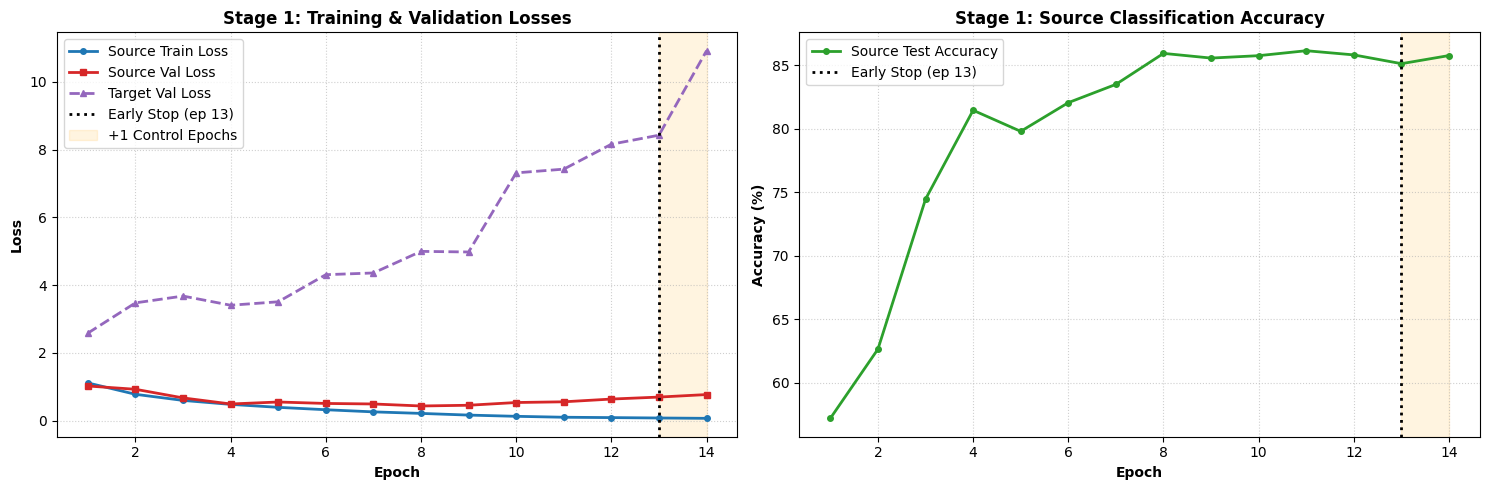

Stage 1 training curves saved to: /content/drive/MyDrive/git/Di/pretrained/stage1_curves_20261116_091201.png


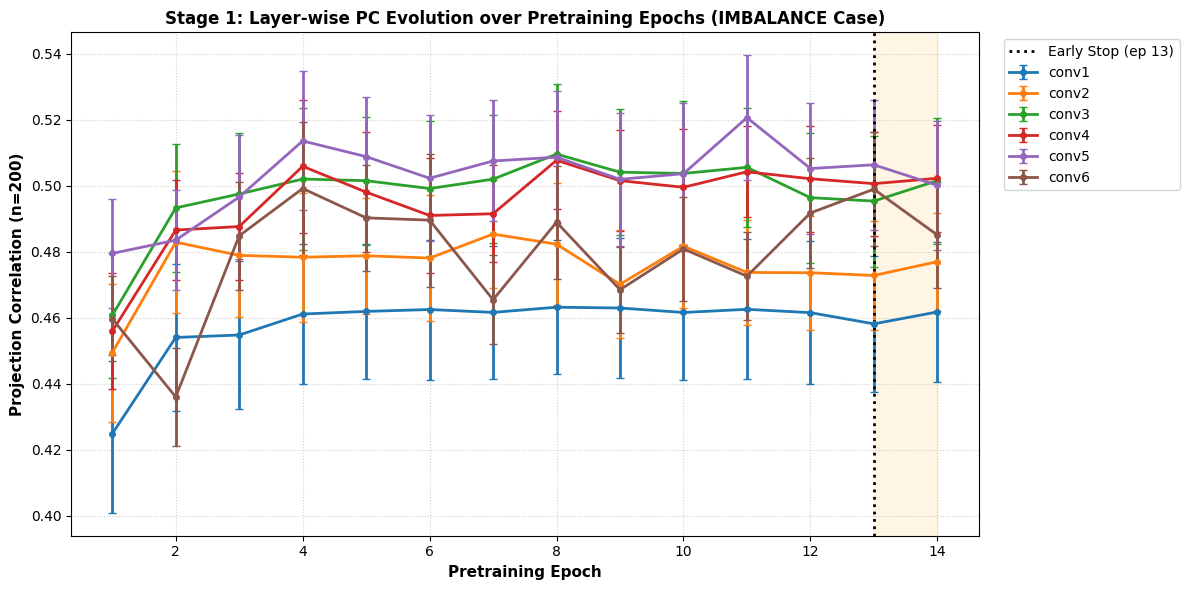

Stage 1 PC evolution plot saved to: /content/drive/MyDrive/git/Di/pretrained/stage1_pc_evolution_20261116_091201.png
[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)
Fixed sample size: n=200 | Early stopping patience: 5 | Max epochs: 50

[Stage 2] Model M_0 (transferred k=0 layers from pre-trained source model)
Fine-tuning on fixed target subset (n=200), monitored metric: Target Validation Loss
[M_0] Epoch 01/50 | Train Loss: 2.4227 | Test Acc: 39.4% | Val Loss: 1.4918 | PC: conv1=0.351±0.026 | conv2=0.338±0.028 | conv3=0.340±0.028 | conv4=0.340±0.030 | conv5=0.338±0.030 | conv6=0.344±0.029 | IPC: conv1=0.355±0.037 | conv2=0.360±0.039 | conv3=0.380±0.039 | conv4=0.386±0.041 | conv5=0.388±0.041 | conv6=0.397±0.041
[M_0] Epoch 02/50 | Train Loss: 1.4129 | Test Acc: 37.4% | Val Loss: 1.3793 | PC: conv1=0.361±0.026 | conv2=0.384±0.026 | conv3=0.405±0.026 | conv4=0.411±0.025 | conv5=0.404±0.025 | conv6=0.395±0.025 | IPC: conv1=0.371±0.036 | conv2=0.420±0.035 

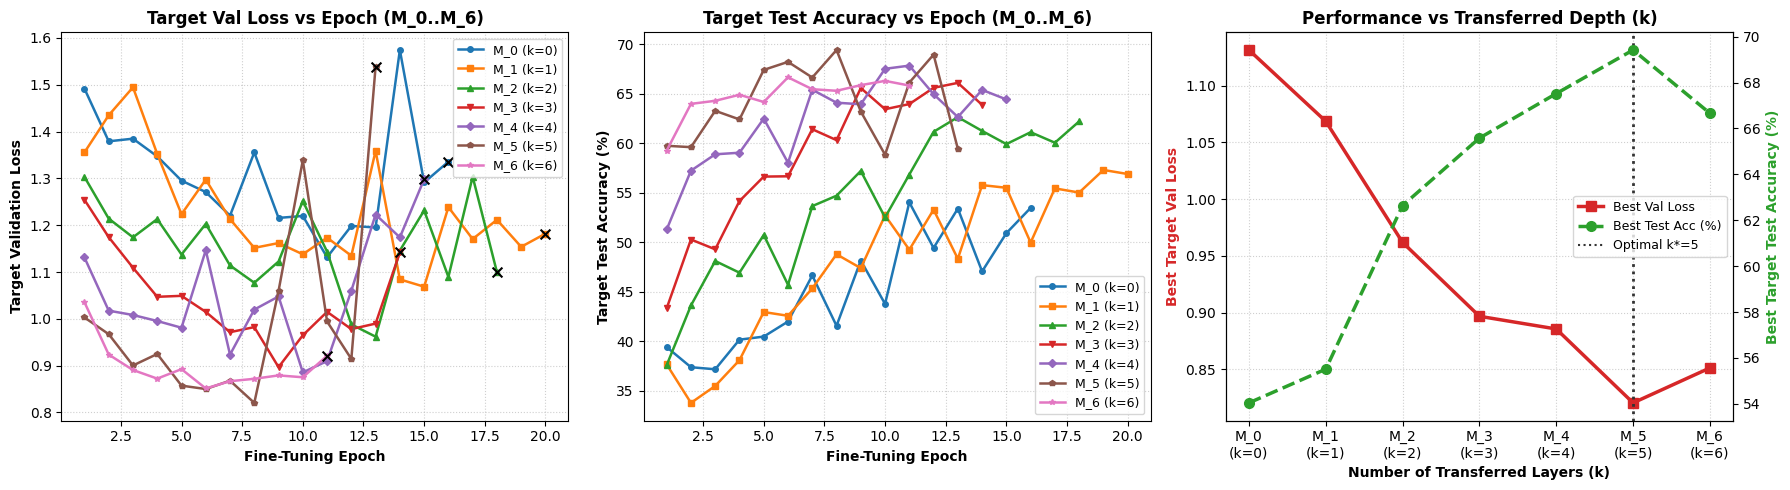

Stage 2 comparative curves saved to: /content/drive/MyDrive/git/Di/pretrained/stage2_curves_comparison_20261116_091203.png


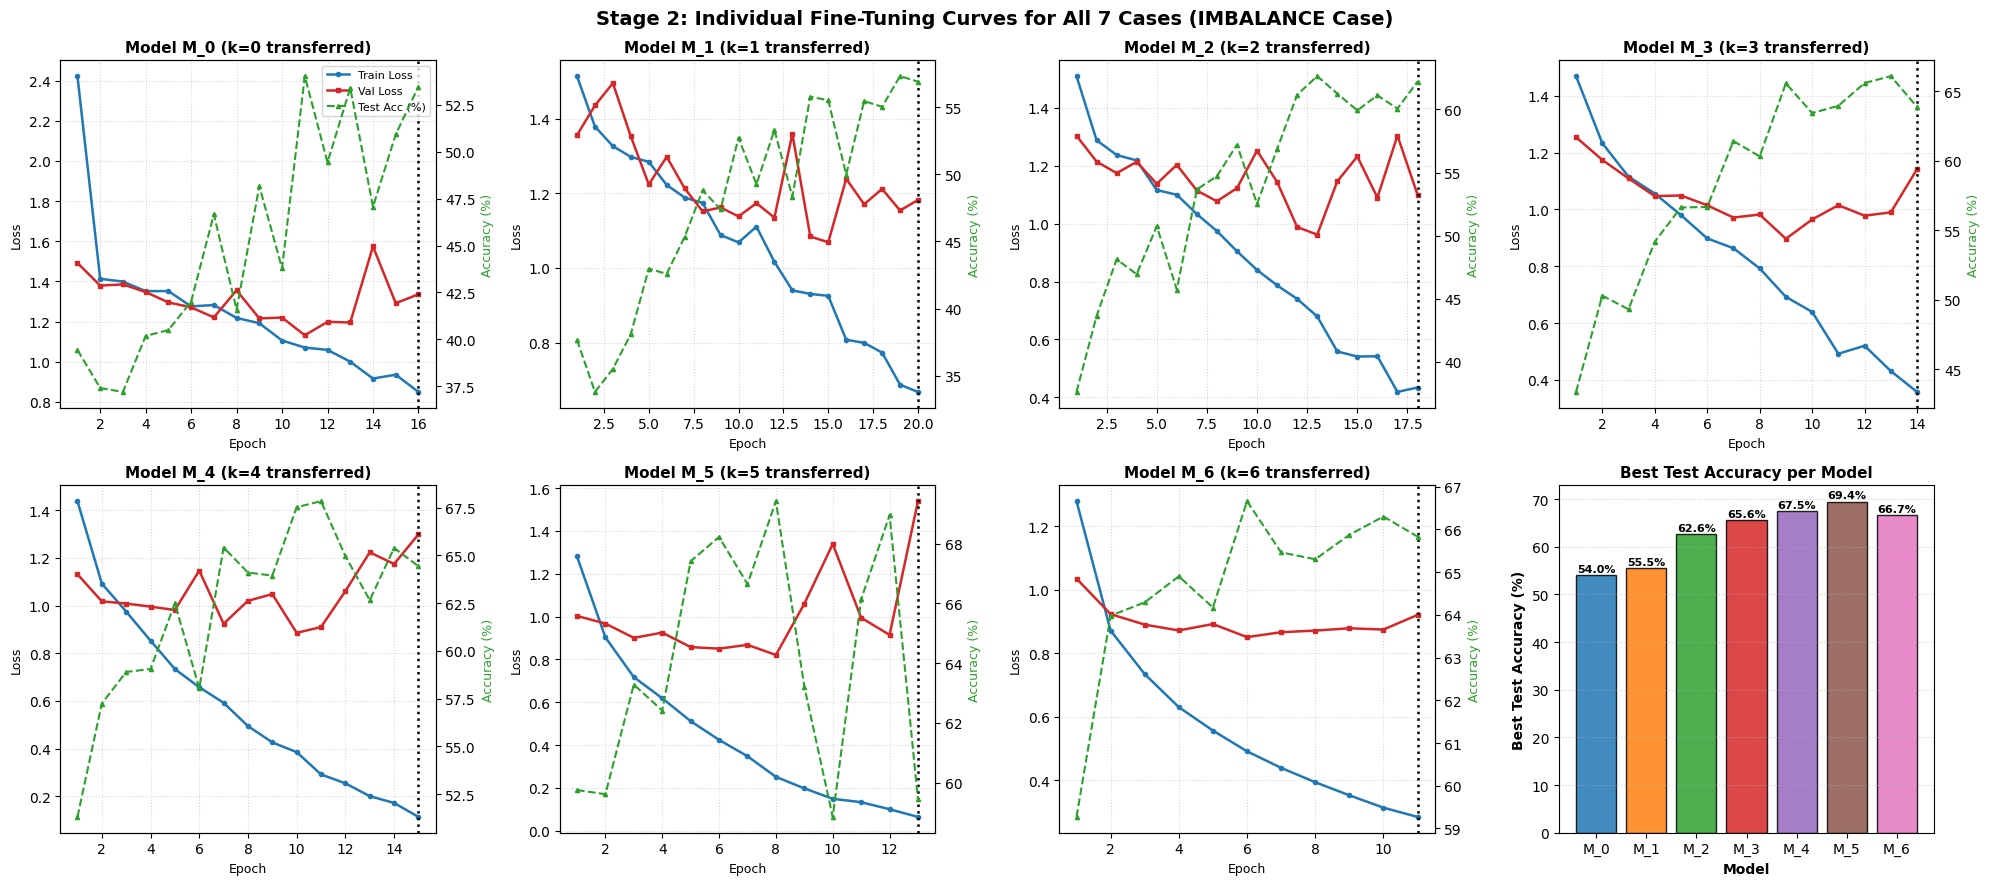

Stage 2 individual curves saved to: /content/drive/MyDrive/git/Di/pretrained/stage2_curves_all_7_cases_20261116_091203.png


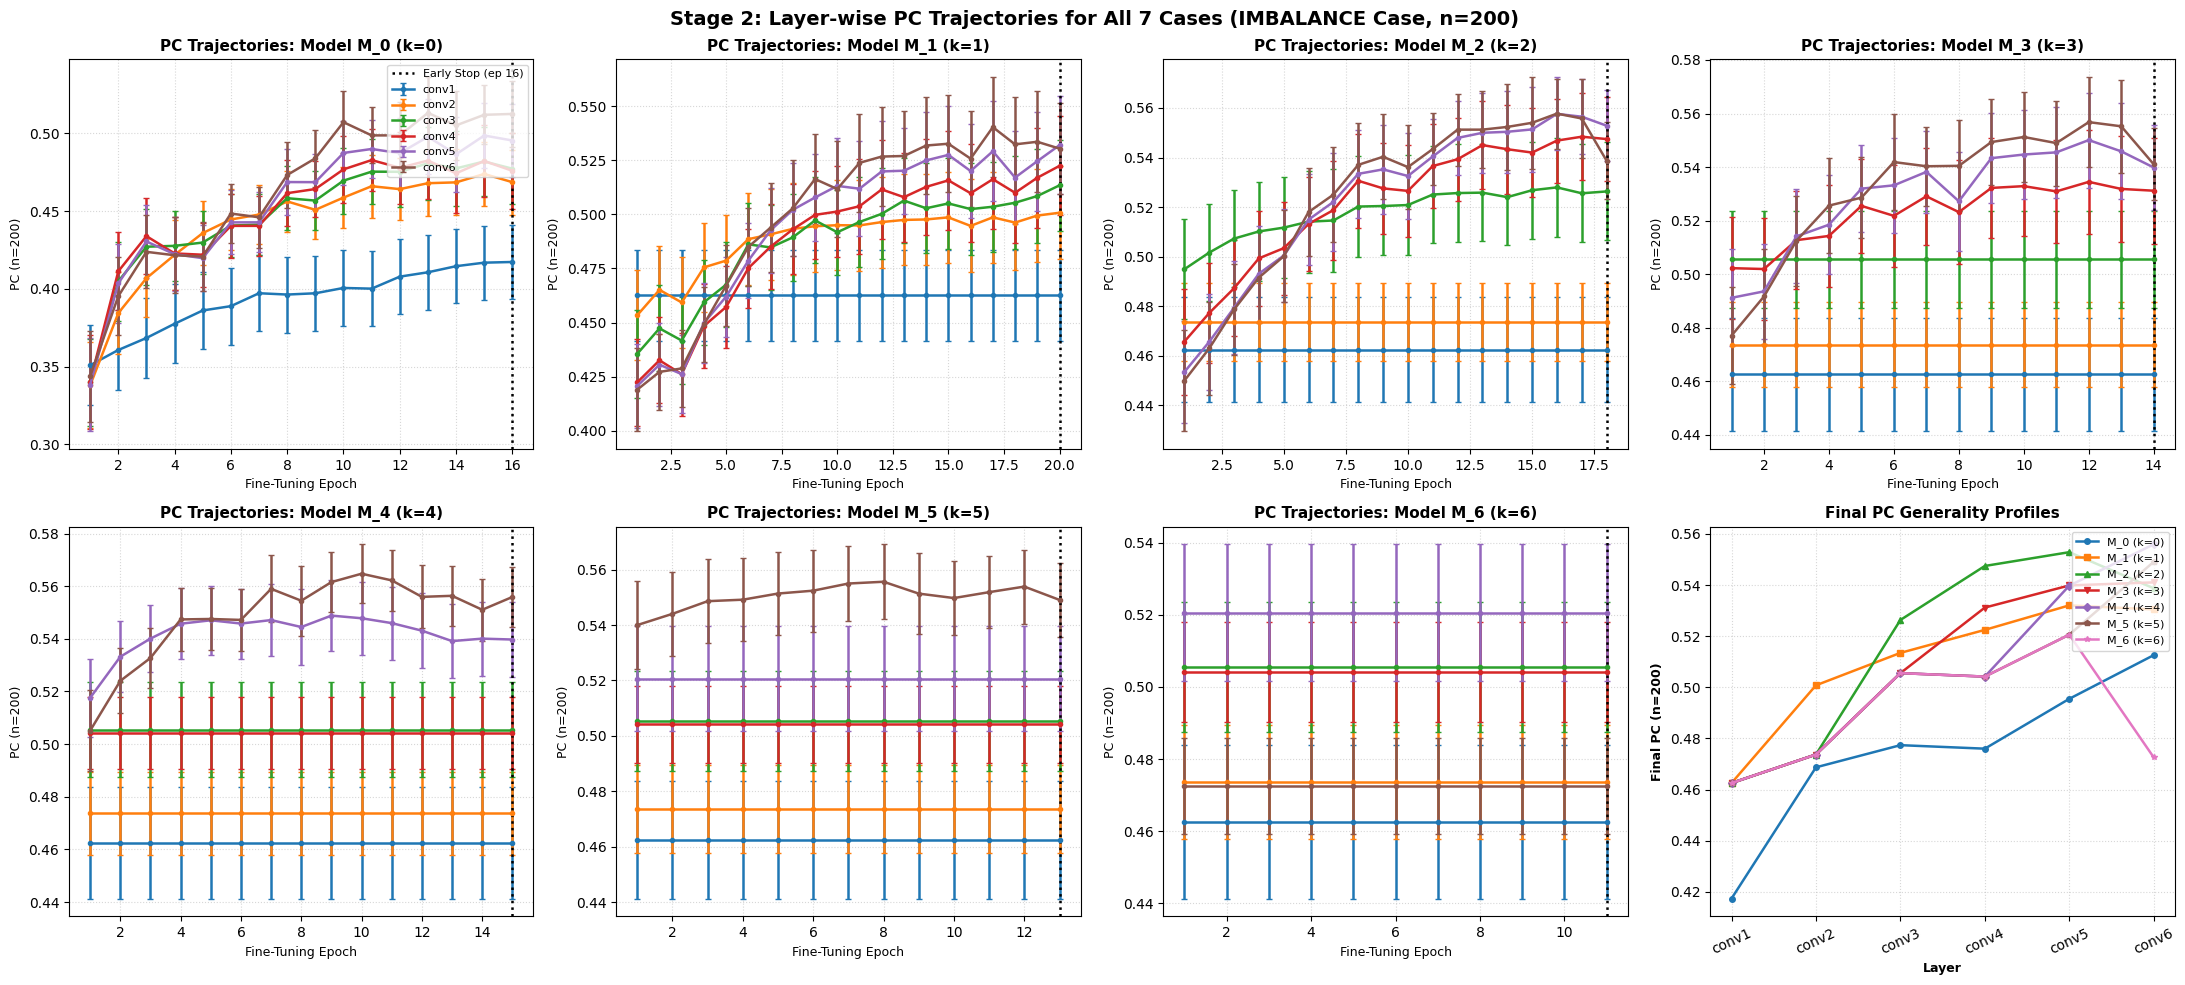

Stage 2 PC trajectories for all 7 cases saved to: /content/drive/MyDrive/git/Di/pretrained/stage2_pc_trajectories_all_7_cases_20261116_091203.png
EXPERIMENT COMPLETED SUCCESSFULLY
Results stored in catalog matching notebook name: '/content/drive/MyDrive/git/Di/pretrained'
Found 288 saved artifacts in '/content/drive/MyDrive/git/Di/pretrained':
  - finetuned_model_20261103_072252.pt (3459.8 KB)
  - finetuned_model_M_0_20261114_191546.pt (3460.1 KB)
  - finetuned_model_M_0_20261114_195144.pt (3460.1 KB)
  - finetuned_model_M_0_20261114_212536.pt (3460.1 KB)
  - finetuned_model_M_0_20261114_220744.pt (3460.1 KB)
  - finetuned_model_M_0_20261115_090703.pt (3460.1 KB)
  - finetuned_model_M_0_20261115_091654.pt (3460.1 KB)
  - finetuned_model_M_0_20261115_092500.pt (3460.1 KB)
  - finetuned_model_M_0_20261115_093235.pt (3460.1 KB)
  - finetuned_model_M_0_20261115_093953.pt (3460.1 KB)
  - finetuned_model_M_0_20261115_101136.pt (3460.1 KB)
  - finetuned_model_M_0_20261115_103804.pt (3460.1 KB

In [10]:
def run_experiment_pipeline(
    seed: int = 42,
    experiment_case: str = "imbalance",
    sample_sizes: Optional[List[int]] = None,
    num_replications: int = 10,
    use_real_cifar10: bool = True,
    pretrain_epochs: int = 50,
    early_stop_patience: int = 5,
    post_early_stop_epochs: int = 1,
    learning_rate_source: float = 0.001,
    target_epochs: int = 50,
    target_patience: int = 5,
    learning_rate_target: float = 0.001,
    feature_extraction: bool = True,
    ft_sample_size: Optional[int] = 1000,
    best_model_criterion: str = 'pc',
    notebook_name: str = "pretrained",
    plot_results: bool = True,
    show_plots: bool = True,
) -> Dict[str, Any]:
    """Execute the full two-stage transfer learning pipeline.

    All calculation parameters are passed explicitly as arguments.
    Can be called repeatedly in a loop across different seeds/configurations
    to gather statistical results.
    """
    # 1. Environment Setup
    device, seed = setup_environment(seed=seed)

    # 2. Experiment Parameters
    params = get_experiment_params(
        experiment_case=experiment_case,
        sample_sizes=sample_sizes,
        num_replications=num_replications,
        use_real_cifar10=use_real_cifar10,
        pretrain_epochs=pretrain_epochs,
        early_stop_patience=early_stop_patience,
        post_early_stop_epochs=post_early_stop_epochs,
        learning_rate_source=learning_rate_source,
        target_epochs=target_epochs,
        target_patience=target_patience,
        learning_rate_target=learning_rate_target,
        feature_extraction=feature_extraction,
        ft_sample_size=ft_sample_size,
        best_model_criterion=best_model_criterion,
        notebook_name=notebook_name,
        seed=seed,
    )

    # 3. Data Loading
    data = load_experiment_data(
        experiment_case=params["EXPERIMENT_CASE"],
        seed=seed,
        use_real_cifar10=params["USE_REAL_CIFAR10"]
    )

    # 4. Selecting and Fixing Target Subsets
    fixed_target_subsets = select_fixed_subsets(
        x_data=data["target_train_x"],
        y_data=data["target_train_y"],
        sample_sizes=params["SAMPLE_SIZES"],
        num_replications=params["NUM_REPLICATIONS"],
        base_seed=seed,
    )

    # 5. Stage 1: Source Pretraining
    stage1_res = run_stage1_pretraining(
        device=device,
        seed=seed,
        loaders=data["loaders"],
        num_source_classes=data["num_source_classes"],
        fixed_target_subsets=fixed_target_subsets,
        primary_sample_size=params["SAMPLE_SIZES"][0],
        num_target_classes=data["num_target_classes"],
        target_test_loader=data["target_test_loader"],
        pretrain_epochs=params["PRETRAIN_EPOCHS"],
        early_stop_patience=params["EARLY_STOP_PATIENCE"],
        post_early_stop_epochs=params["POST_EARLY_STOP_EPOCHS"],
        learning_rate_source=params["LEARNING_RATE_SOURCE"],
        best_model_criterion=params["BEST_MODEL_CRITERION"],
        experiment_case=params["EXPERIMENT_CASE"],
        results_dir=params["RESULTS_DIR"]
    )

    # 6. Stage 1 Visualizations
    stage1_plots = None
    if plot_results:
        stage1_plots = plot_stage1_visualizations(
            stage1_history=stage1_res["stage1_history"],
            stage1_ts=stage1_res["stage1_ts"],
            primary_sample_size=params["SAMPLE_SIZES"][0],
            experiment_case=params["EXPERIMENT_CASE"],
            early_stop_epoch=stage1_res["early_stop_epoch"],
            post_early_stop_epochs=params["POST_EARLY_STOP_EPOCHS"],
            results_dir=params["RESULTS_DIR"],
            show_plots=show_plots
        )

    # 7. Stage 2: Target Fine-Tuning
    stage2_res = run_stage2_finetuning(
        best_source_state=stage1_res["best_source_state"],
        source_model=stage1_res["source_model"],
        loaders=data["loaders"],
        target_test_loader=data["target_test_loader"],
        fixed_target_subsets=fixed_target_subsets,
        device=device,
        target_train_x=data["target_train_x"],
        target_train_y=data["target_train_y"],
        num_target_classes=data["num_target_classes"],
        primary_sample_size=params["SAMPLE_SIZES"][0],
        ft_sample_size=params["FT_SAMPLE_SIZE"],
        target_epochs=params["TARGET_EPOCHS"],
        target_patience=params["TARGET_PATIENCE"],
        learning_rate_target=params["LEARNING_RATE_TARGET"],
        feature_extraction=params["FEATURE_EXTRACTION"],
        experiment_case=params["EXPERIMENT_CASE"],
        results_dir=params["RESULTS_DIR"],
        seed=seed,
        generator=data["generator"]
    )

    # 8. Stage 2 Visualizations
    stage2_plots = None
    if plot_results:
        stage2_plots = plot_stage2_visualizations(
            stage2_results=stage2_res["stage2_results"],
            stage2_ts=stage2_res["stage2_ts"],
            primary_sample_size=params["SAMPLE_SIZES"][0],
            experiment_case=params["EXPERIMENT_CASE"],
            results_dir=params["RESULTS_DIR"],
            show_plots=show_plots
        )

    # 9. Experiment Summary
    artifacts = summarize_experiment(results_dir=params["RESULTS_DIR"])

    return {
        "params": params,
        "seed": seed,
        "stage1_results": stage1_res,
        "stage2_results": stage2_res,
        "stage1_plots": stage1_plots,
        "stage2_plots": stage2_plots,
        "artifacts": artifacts
    }


# =========================================================================
# 1. Execution of the pipeline with explicit parameters
# =========================================================================
# All calculation parameters are passed explicitly as arguments:
results = run_experiment_pipeline(
    seed=42,
    experiment_case="imbalance",
    sample_sizes=[200],
    num_replications=10,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=1000,
    best_model_criterion='pc',
    notebook_name="pretrained",
    plot_results=True,
    show_plots=True
)

# =========================================================================
# 2. Example: Multi-run loop for statistical analysis across multiple seeds
# =========================================================================
# To gather statistics across multiple runs, iterate over seeds:
#
# seeds_to_run = [42, 43, 44, 45, 46]
# multi_run_stats = []
# for s in seeds_to_run:
#     print(f"\n{'='*75}\n>>> Running Experiment Replication with Seed={s} <<<\n{'='*75}\n")
#     res = run_experiment_pipeline(
#         seed=s,
#         experiment_case="imbalance",
#         sample_sizes=[200],
#         num_replications=10,
#         use_real_cifar10=True,
#         pretrain_epochs=50,
#         early_stop_patience=5,
#         post_early_stop_epochs=1,
#         target_epochs=50,
#         target_patience=5,
#         learning_rate_target=0.001,
#         feature_extraction=True,
#         ft_sample_size=1000,
#         best_model_criterion='pc',
#         notebook_name="pretrained_stats",
#         plot_results=False  # disable plots during batch runs
#     )
#     best_k = res["stage2_results"]["best_k_idx"]
#     best_model_metrics = res["stage2_results"]["stage2_results"][best_k]
#     multi_run_stats.append({
#         "seed": s,
#         "optimal_k": best_k,
#         "best_val_loss": best_model_metrics["best_val_loss"],
#         "best_test_acc": best_model_metrics["best_test_acc"],
#         "early_stop_epoch": best_model_metrics["early_stop_epoch"]
#     })
